# Домашнее задание 3. Фреймворк, критик, голосование: что окупается

Один агент (Википедия, свежие вопросы о 2026 годе, 124 вопроса) исполняется четырьмя способами, и к лучшему из них добавляются паттерны недели. Все деньги считает счётчик на уровне HTTP. Порядок ноутбука повторяет шаги задания; результаты каждой конфигурации сохраняются в `results/`, повторный запуск не тратит деньги.

## Подготовка

Ключ OpenRouter в `.env` в корне репозитория, данные в `data/`. Модели: `gpt-4o-mini` (дешёвая), `claude-sonnet-4.6` (сильная). Снимок Википедии `data/wiki_snapshot.json.gz` делает прогон воспроизводимым.

In [ ]:
import os, re, json, gzip, time, warnings
os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict
import httpx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

BASE_URL = "https://openrouter.ai/api/v1"
CHEAP, MID, STRONG = "openai/gpt-4o-mini", "anthropic/claude-haiku-4.5", "anthropic/claude-sonnet-4.6"
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("/kaggle/input/seminar03-data"), Path("/kaggle/input/seminar03-data/data")]
             if (p / "fresh_2026.jsonl").exists()), Path("data"))
SAMPLE, STRONG_SAMPLE = 124, 124
Path("img").mkdir(exist_ok=True)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6, timeout=600):
    """Параллельный map; зависший вопрос через timeout секунд записывается как ошибка, а не вешает весь прогон."""
    ex = ThreadPoolExecutor(workers)
    futures = [ex.submit(fn, item) for item in items]
    out = []
    for f in futures:
        try:
            out.append(f.result(timeout=timeout))
        except Exception as e:
            out.append(f"ошибка: {type(e).__name__}")
    ex.shutdown(wait=False, cancel_futures=True)
    return out

## Шаг 1. Счётчик и базовая линия

Все исполнения (голый цикл, LangGraph, smolagents) ходят в OpenRouter через один `httpx.Client` с крючком на ответ. Из запроса берём модель и число сообщений/инструментов, из ответа поле `usage` (токены и `cost`). Каждый вызов получает метку конфигурации `TAG`.

In [ ]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}

In [ ]:
def on_response(response):
    response.read()
    request = json.loads(response.request.content or b"{}")
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag":TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0

    })



In [4]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=90)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-seminar03"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200:
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,prompt,completion,cost
0,проверка счётчика,gpt-4o-mini,1,0,9,2,0.000003


### Инструменты и голый цикл

`web_search` и `page_find` по Википедии (снимок + живые запросы) и голый цикл на 20 строк с детектором повторов и последним шагом без инструментов.

In [5]:
tasks = load_jsonl("fresh_2026.jsonl")[:SAMPLE]
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar03/1.0 (https://t.me/artemovma)"}
SNAPSHOT = DATA / "wiki_snapshot.json.gz"
WIKI_CACHE = json.loads(gzip.decompress(SNAPSHOT.read_bytes())) if SNAPSHOT.exists() else {}

def wiki(params):
    key = json.dumps(params, sort_keys=True)
    for attempt in range(4):
        if key not in WIKI_CACHE:
            try:
                r = httpx.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=25)
                r.raise_for_status()
                WIKI_CACHE[key] = r.json().get("query", {})
            except httpx.HTTPError as e:
                error = e
                time.sleep(2 * (attempt + 1))
                continue
        return WIKI_CACHE[key]
    raise RuntimeError(f"Википедия не отвечает: {error}")

def web_search(query: str) -> str:
    """Search English Wikipedia: returns the intro of the best article and the titles of two more articles."""
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3}).get("search", [])
    if not hits:
        return "nothing found"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}).get("pages", {})
    intro = " ".join(next(iter(pages.values()), {}).get("extract", "").split())[:1200]
    return f"[{hits[0]['title']}] {intro} | other articles: " + ", ".join(h["title"] for h in hits[1:])

def page_find(title: str, keywords: str) -> str:
    """Look inside the full text of a Wikipedia article and return the lines that contain the keywords."""
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}).get("pages", {})
    text = next(iter(pages.values()), {}).get("extract", "")
    if not text:
        return "no such page"
    kws = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [l.strip() for l in text.splitlines() if l.strip() and sum(w in l.lower() for w in kws) >= max(1, (len(kws) + 1) // 2)]
    return "\n".join(l[:350] for l in lines[:5]) or "keywords not found on the page"

len(tasks), sum(t["agent_ok"] for t in tasks), len(WIKI_CACHE), web_search("2026 Winter Paralympics")[:200], page_find("2026 in Ukraine", "Paralympics boycott")

(124,
 72,
 1640,
 '[2026 Winter Paralympics] The 2026 Winter Paralympics (Italian: Giochi paralimpici invernali di Milano Cortina 2026), also known as the Milano Cortina 2026 Winter Paralympic Games, were the 14th editi',
 'Ukraine boycotts the opening ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.\n15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.')

In [ ]:
AGENT_SYSTEM = ("You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. "
                "When done, reply with the short answer only, no explanation.")
BARE_TOOLS = [
    {"type": "function", "function": {"name": "web_search", "description": web_search.__doc__,
     "parameters": {"type": "object", "properties": {"query": {"type": "string", "description": "short query: a name, a title, an event"}}, "required": ["query"]}}},
    {"type": "function", "function": {"name": "page_find", "description": page_find.__doc__,
     "parameters": {"type": "object", "properties": {"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"},
                                                     "keywords": {"type": "string", "description": "two to five keywords"}},
                    "required": ["title", "keywords"]}}}]
FUNCS = {"web_search": web_search, "page_find": page_find}
LAST_STEP = "No more tool calls. Answer now with what you found."

def bare_agent(question, model=CHEAP, max_steps=6):
    messages, seen = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set()
    for step in range(max_steps):
        last = step == max_steps - 1
        if last:
            messages.append({"role": "user", "content": LAST_STEP})
        msg = chat(messages, model, None if last else BARE_TOOLS)
        messages.append({k: v for k, v in msg.items() if k in ("role", "content", "tool_calls") and v})
        calls = msg.get("tool_calls") or []
        if not calls:
            return msg.get("content") or ""
        for c in calls:
            key = (c["function"]["name"], c["function"]["arguments"])
            result = "repeated call, answer now" if key in seen else FUNCS[key[0]](**json.loads(key[1]))
            seen.add(key)
            messages.append({"role": "tool", "tool_call_id": c["id"], "content": result})
    return messages[-1].get("content") or ""

### Проверка ответа и прогон

`is_correct` из семинара: все слова эталона после нормализации есть в ответе. Её качество разбираем в разделе «Проверка проверки». `run_config` прогоняет конфигурацию на всех вопросах и кэширует итог в `results/`; `report` считает строку таблицы.

In [7]:
ESCALATED = []
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen twenty".split())}
NUMBERS.update({w: f"{n}th" for n, w in enumerate("zeroth first second third fourth fifth sixth seventh eighth ninth tenth eleventh twelfth".split())} | {"first": "1st", "second": "2nd", "third": "3rd"})

def norm(text):
    return " ".join(NUMBERS.get(w, w) for w in re.sub(r"\b(a|an|the|people|persons)\b|[^\w\s]", " ", str(text).lower()).split())

def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())

RESULTS = {}
RES = Path("results"); RES.mkdir(exist_ok=True)

def run_config(tag, fn, sample=None, workers=6):
    """Прогон конфигурации. Итог (ответы, вызовы, эскалации) пишется в results/<метка>.json; повторный запуск берёт его оттуда и ничего не стоит."""
    sample = sample or tasks
    path = RES / (re.sub(r"\W+", "_", tag) + ".json")
    if path.exists():
        saved = json.loads(path.read_text(encoding="utf-8"))
        by_id = {t["id"]: t for t in tasks}
        RESULTS[tag] = [{**r, "ok": is_correct(by_id[r["id"]], r["answer"])} for r in saved["results"]]
        CALLS.extend(saved["calls"])
        if tag.startswith("каскад"):
            ESCALATED[:] = saved["escalated"]
        return report([tag])
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    saved = {"results": RESULTS[tag], "calls": [c for c in CALLS if c["tag"] == tag], "escalated": list(ESCALATED)}
    path.write_text(json.dumps(saved, ensure_ascii=False), encoding="utf-8")
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(r["ok"] for r in res), sum(c["cost"] for c in calls)
        rows.append({"конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"эталон": t["answer"], "ответ": str(r["answer"])[:110]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])

TAG["now"] = "проба"
print(bare_agent(tasks[0]["question"]), "| эталон:", tasks[0]["answer"])
run_config("голый цикл, mini", bare_agent)

Ukraine boycotted the closing ceremony of the 2026 Winter Paralympics on March 15, 2026. | эталон: 15 March


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",77/124,0.621,3.7,1987,0.0337,0.0543


In [8]:
wrong("голый цикл, mini")

,эталон,ответ
0,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...
1,Ciudad Rodrigo,I could not find specific information about a ...
2,Oleksandr Syrskyi,The information regarding the dismissal of the...
3,Disney Kids & Family,Disney Branded Television rebranded itself as ...
4,German Galushchenko,I couldn't find specific information about an ...
5,Markus Hinterhäuser,Anna Netrebko was placed on leave until Septem...
6,nine,Six people were killed in the mass shooting at...
7,Richard Lewer,I couldn't find the winner of the Archibald Pr...
8,Marilyn Gladu,Robert Jenrick.
9,6.3,I couldn't find the specific magnitude of the ...


## Шаг 2. Фреймворк и его налог

Тот же агент на LangGraph (`create_agent`): те же инструменты, тот же системный промпт, та же модель. Сначала «как есть», потом с двумя починками: описания аргументов через Pydantic (`args_schema`) и последний шаг без инструментов (middleware).

In [ ]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

LC_TOOLS = [tool(web_search), tool(page_find)]
LG_MIDDLEWARE = []

def lc_model(model=CHEAP, temperature=0.0):
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature, timeout=60, max_retries=2) #!

In [ ]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]


In [11]:
def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content

TAG["now"] = "проба"
print(ask_langgraph(tasks[0]["question"]), "| эталон:", tasks[0]["answer"])
run_config("LangGraph как есть, mini", ask_langgraph)
wrong("LangGraph как есть, mini", 15)

Ukraine boycotted the closing ceremony of the 2026 Winter Paralympics on March 15, 2026. | эталон: 15 March


,эталон,ответ
0,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...
1,a strategic partnership agreement,ошибка: GraphRecursionError
2,A total fire ban,ошибка: GraphRecursionError
3,Deniz Göktaş,ошибка: GraphRecursionError
4,41.5 °C,ошибка: GraphRecursionError
5,Ciudad Rodrigo,ошибка: GraphRecursionError
6,Oleksandr Syrskyi,ошибка: GraphRecursionError
7,EOS-05,ошибка: GraphRecursionError
8,13 July,ошибка: GraphRecursionError
9,Disney Kids & Family,ошибка: GraphRecursionError


In [ ]:
SIMPLE = "What is 2 + 2? Reply with the number only."
TAG["now"] = "схема: голый цикл"
bare_agent(SIMPLE)
TAG["now"] = "схема: LangGraph как есть"
create_agent(lc_model(CHEAP), tools=[tool(web_search), tool(page_find)], system_prompt=AGENT_SYSTEM).invoke({"messages": [{"role": "user", "content": SIMPLE}]})
for tag in ["схема: голый цикл", "схема: LangGraph как есть"]:
    print(tag, json.dumps(FIRST[tag]["tools"][1]["function"]["parameters"]["properties"], ensure_ascii=False))

схема: голый цикл {"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"}, "keywords": {"type": "string", "description": "two to five keywords"}}
схема: LangGraph как есть {"title": {"type": "string"}, "keywords": {"type": "string"}}


Фреймворк «как есть» молча потерял описания аргументов (ячейка выше) и падал с `GraphRecursionError` на последнем шаге. Починки ниже.

In [ ]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

class SearchArgs(BaseModel):
    query: str = Field(description="short query: a name, a title, an event")

class FindArgs(BaseModel):
    title: str = Field(description="exact article title, e.g. 2026 in Japan")
    keywords: str = Field(description="two to five keywords")

LC_TOOLS = [tool(web_search, args_schema=SearchArgs), tool(page_find, args_schema=FindArgs)]

In [ ]:
@wrap_model_call
def last_step_without_tools(request, handler):
    if sum(m.type == 'ai' for m in request.messages) >= 5:
        request = request.override(tools=[], messages=request.messages + [HumanMessage(LAST_STEP)])
    return handler(request)
    


In [15]:
LG_MIDDLEWARE.append(last_step_without_tools)
run_config("LangGraph, mini", ask_langgraph)
report(["голый цикл, mini", "LangGraph как есть, mini", "LangGraph, mini"])

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",77/124,0.621,3.7,1987,0.0337,0.0543
1,"LangGraph как есть, mini",61/124,0.492,4.4,2647,0.0421,0.0857
2,"LangGraph, mini",80/124,0.645,3.7,1902,0.0322,0.0499


### «Пустой запрос»: что уходит в первом вызове

Вопрос `2 + 2` без поиска: токены первого запроса у голого цикла и у фреймворков, и побайтное сравнение запроса голого цикла с запросом LangGraph. Дополнительная строка для сравнения: smolagents (ToolCallingAgent и CodeAgent).

In [ ]:
from smolagents import ToolCallingAgent, CodeAgent, OpenAIServerModel, tool as smol_tool

def smol_model(model=CHEAP):
    return OpenAIServerModel(model_id=model, api_base=BASE_URL, api_key=KEY, client_kwargs={"http_client": HTTP, "timeout": 60}, temperature=0)

@smol_tool
def smol_page_find(title: str, keywords: str) -> str:
    """Look inside the full text of a Wikipedia article and return the lines that contain the keywords.

    Args:
        title: exact article title, e.g. 2026 in Japan
        keywords: two to five keywords
    """
    return page_find(title, keywords)

In [ ]:
@smol_tool
def smol_web_search(query: str) -> str:
    """Search English Wikipedia: returns the intro of best acticle

    Args:
            query: short query: a name, a date, an event
    """
    return web_search(query)


In [ ]:
def ask_smol(question, kind="tools", model=CHEAP):
    cls = ToolCallingAgent if kind == "tools" else CodeAgent
    agent = cls(tools=[smol_web_search, smol_page_find], model=smol_model(model), instructions=AGENT_SYSTEM, max_steps=10, verbosity_level=0)
    return str(agent.run(question))




In [19]:
PROBE = "What is 2 + 2? Reply with the number only."
for tag, fn in [("пустой вопрос: голый цикл", bare_agent), ("пустой вопрос: LangGraph", ask_langgraph),
                ("пустой вопрос: smolagents, инструменты", lambda q: ask_smol(q, "tools")),
                ("пустой вопрос: smolagents, код", lambda q: ask_smol(q, "code"))]:
    TAG["now"] = tag
    fn(PROBE)
empty = pd.DataFrame([c for c in CALLS if c["tag"].startswith("пустой")])
empty.groupby("tag", sort=False).agg(вызовов=("prompt", "size"), первый_запрос=("prompt", "first"), всего_токенов=("prompt", "sum"),
                                      центов=("cost", lambda s: round(s.sum() * 100, 4)))

,вызовов,первый_запрос,всего_токенов,центов
tag,,,,
пустой вопрос: голый цикл,1,176,176,0.0028
пустой вопрос: LangGraph,1,176,176,0.0028
"пустой вопрос: smolagents, инструменты",1,1125,1125,0.0177
"пустой вопрос: smolagents, код",1,2132,2132,0.0177


In [ ]:
content = FIRST["пустой вопрос: smolagents, код"]["messages"][0]["content"]
system_text = content if isinstance(content, str) else " ".join(part.get("text", "") for part in content)
print(len(system_text), "символов системного промпта у CodeAgent. Начало:\n")
print(system_text[:1200])

9128 символов системного промпта у CodeAgent. Начало:

You are an expert assistant who can solve any task using code blobs. You will be given a task to solve as best you can.
To do so, you have been given access to a list of tools: these tools are basically Python functions which you can call with code.
To solve the task, you must plan forward to proceed in a series of steps, in a cycle of Thought, Code, and Observation sequences.

At each step, in the 'Thought:' sequence, you should first explain your reasoning towards solving the task and the tools that you want to use.
Then in the Code sequence you should write the code in simple Python. The code sequence must be opened with '<code>', and closed with '</code>'.
During each intermediate step, you can use 'print()' to save whatever important information you will then need.
These print outputs will then appear in the 'Observation:' field, which will be available as input for the next step.
In the end you have to return a final answer u

In [ ]:
def canon(request):
    return json.dumps({k: v for k, v in request.items() if k not in ("stream",)}, sort_keys=True)

bare, lg = FIRST["пустой вопрос: голый цикл"], FIRST["пустой вопрос: LangGraph"]
print("запрос голого цикла и LangGraph совпадает (с точностью до порядка ключей и поля stream):", canon(bare) == canon(lg))
print("лишние поля LangGraph:", set(lg) - set(bare))
print("размер схемы инструментов, символов:", len(json.dumps(bare["tools"])), len(json.dumps(lg["tools"])))

запрос голого цикла и LangGraph совпадает (с точностью до порядка ключей и поля stream): True
лишние поля LangGraph: {'stream'}
размер схемы инструментов, символов: 751 751


### Фреймворки на всём наборе

In [22]:
run_config("smolagents инструменты, mini", lambda q: ask_smol(q, "tools"))
run_config("smolagents код, mini", lambda q: ask_smol(q, "code"))
report()

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",77/124,0.621,3.7,1987,0.0337,0.0543
1,"LangGraph как есть, mini",61/124,0.492,4.4,2647,0.0421,0.0857
2,"LangGraph, mini",80/124,0.645,3.7,1902,0.0322,0.0499
3,"smolagents инструменты, mini",80/124,0.645,4.5,8335,0.0910,0.1411
4,"smolagents код, mini",40/124,0.323,5.0,15771,0.1643,0.5095


## Шаг 3. Два паттерна недели

К лучшему исполнению (LangGraph с починками на mini) добавляем: **критика с опорой** и **голосование с каскадом**. Бонусом идёт план.

### Паттерн 1. Критик с опорой

Граф `answer → critic → (answer | END)`. Критик проверяет ответ по тексту, который агент реально нашёл (`evidence`), вердикт по схеме `Verdict`, не больше двух попыток. Считаем, сколько неверных ответов критик исправил и сколько верных испортил.

In [ ]:
from langgraph.graph import StateGraph, START, END

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = ("You check a short answer against the evidence the agent retrieved from Wikipedia. Judge only by the evidence. "
                 "If the evidence does not contain the answer, the answer is not supported.")

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [ ]:
def critic_node(state):
    judge = lc_model(CHEAP).with_structured_output(Verdict)
    verdict = judge.invoke([
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}


In [ ]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return 'answer'
    return END


In [ ]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [27]:
run_config("LangGraph + критик, mini", ask_checked)
base, crit = RESULTS["LangGraph, mini"], RESULTS["LangGraph + критик, mini"]
fixed = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
broken = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
print("исправил", fixed, "| испортил", broken)
report(["LangGraph, mini", "LangGraph + критик, mini"])

исправил 8 | испортил 4


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",80/124,0.645,3.7,1902,0.0322,0.0499
1,"LangGraph + критик, mini",84/124,0.677,6.6,3869,0.0642,0.0948


### Паттерн 2. Голосование и каскад

Три независимых прогона агента при температуре 0.7, ответ большинством. Если согласны не все три, вопрос уходит Sonnet. Согласие меряем на коротких ответах (`bag` сравнивает ответ как набор слов). Sonnet в одиночку считаем на первых `STRONG_SAMPLE` вопросах.

In [ ]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

In [ ]:
SHORT = " Answer with at most five words: a name, a date, a number or a short phrase."

def vote(question, k=3):
    answers = pmap(lambda _: ask_langgraph(question, CHEAP, 0.7, extra=SHORT), range(k), k, timeout=300)
    keys = [bag(a) for a in answers]
    top, n = Counter(keys).most_common(1)[0]
    return {"answer": answers[keys.index(top)], "agreement": n / k}


In [ ]:
def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]
    ESCALATED.append(question)
    return ask_langgraph(question, STRONG)
    


In [31]:
ESCALATED = []
head = tasks[:STRONG_SAMPLE]
run_config("голосование 3, mini", lambda q: vote(q, 3)["answer"], sample=head, workers=3)
run_config("каскад: 3 голоса mini, иначе Sonnet", cascade, sample=head, workers=3)
run_config("LangGraph, Sonnet", lambda q: ask_langgraph(q, STRONG), sample=head, workers=3)
print("ушло наверх:", len(ESCALATED), "из", len(head))
report(["голосование 3, mini", "каскад: 3 голоса mini, иначе Sonnet", "LangGraph, Sonnet"])

ушло наверх: 78 из 124


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голосование 3, mini",82/124,0.661,11.2,6161,0.1016,0.1536
1,"каскад: 3 голоса mini, иначе Sonnet",93/124,0.750,13.9,9613,1.3123,1.7497
2,"LangGraph, Sonnet",95/124,0.766,3.6,4455,1.6347,2.1338


## Проверка проверки

`is_correct` решает, верен ли ответ, и может ошибаться так же тихо, как модель. Для двух конфигураций, где есть сомнения (критик и каскад), читаем глазами по 10 ответов, которые проверка сочла неверными (случайная выборка, `seed=0`). Ниже сами ответы, в следующей ячейке: что оказалось верным и что поправлено.

In [32]:
import random

def review(tag, n=10):
    rows = [(t["id"], t["answer"], r["answer"]) for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]]
    random.Random(0).shuffle(rows)
    return pd.DataFrame([{"id": i, "эталон": g, "ответ": str(a).replace("\n", " ")[:140]} for i, g, a in rows[:n]])

review("LangGraph + критик, mini")

,id,эталон,ответ
0,fresh-2,Miguel Díaz-Canel,Iran entered negotiations with the Trump admin...
1,fresh-100,10-day,The duration of the ceasefire in the 2026 Leba...
2,fresh-41,Prime Minister Narendra Modi,The information does not specify who inaugurat...
3,fresh-77,13.2 months,The median overall survival time for patients ...
4,fresh-102,José María Balcázar,Keiko Fujimori replaced José Jerí as president...
5,fresh-56,Yoon Suk Yeol,Jair Bolsonaro.
6,fresh-122,Burkina Faso,I could not find any information indicating th...
7,fresh-110,prime minister,Keir Starmer resigned as the leader of the Lab...
8,fresh-13,Ciudad Rodrigo,Madrid experienced a fatal incident during the...
9,fresh-75,life imprisonment,Yoon Suk Yeol is currently serving a life sent...


In [33]:
review("каскад: 3 голоса mini, иначе Sonnet")

,id,эталон,ответ
0,fresh-27,nine,Six people killed.
1,fresh-41,Prime Minister Narendra Modi,"Based on the information found, the Noida Inte..."
2,fresh-83,eight games,8
3,fresh-77,13.2 months,"Based on my research, I was unable to find a s..."
4,fresh-32,Marilyn Gladu,"Based on my research, I was unable to find spe..."
5,fresh-2,Miguel Díaz-Canel,"Based on my research, I was unable to find a s..."
6,fresh-35,129,**136 people** were killed in the earthquake t...
7,fresh-123,Kehl,I was unable to find information about a night...
8,fresh-107,Michaelmas Island,I was unable to find the specific location of ...
9,fresh-61,13 years,"Based on the information found, in March 2026,..."


### Что нашли и что поправили

Просмотр шёл в несколько заходов; после каждой правки выборка меняется, потому что неверных ответов становится меньше:

1. Критик и каскад, по 10 ответов. **Верными оказались 2 из 20.** `11th` против `eleventh` (проверка не знала порядковых числительных) и fresh-28: Википедия обновила число погибших в Адамусе с 43 до 46, эталон устарел (то же, что с 43 до 46 на семинаре).
2. Критик, ещё 10. **2 верных**: «28» против эталона «28 people» и `14` против `Fourteen` (числа словами работали только до двенадцати).
3. Итоговый прогон (ячейки выше). Критик: **1 верный из 10**: `life sentence` против эталона `life imprisonment` (синоним). Каскад: **1 верный из 10**: `8` против эталона `eight games` (в ответе нет слова `games`). Остальные настоящие: отказы вида «не нашёл» и неверные имена (`Keiko Fujimori` вместо `José María Balcázar`).

Поправлено: порядковые числительные и числа словами до двадцати, слово `people` не учитывается, эталон fresh-28 заменён на 46. Результаты пересчитываются из сохранённых ответов, без новых вызовов моделей. Не поправлено: синонимы (`sentence`/`imprisonment`), эталоны с существительным после числа (`eight games`), сокращения единиц (`bn`, `m`) и два вопроса с расхождением чисел (`136` против `129` в fresh-35, `Six` против `nine` в fresh-27): возможно, Википедия обновила и их, но по текущей странице я это не проверял, поэтому они остаются неверными. Подгонять проверку дальше под эти же данные не стал: это превратилось бы в подгонку под тест. Все оставшиеся промахи этого рода занижают долю верных на 1–3 ответа из 10 просмотренных неверных на конфигурацию.

## Шаг 4. Итог: одна таблица и одна картинка

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",77/124,0.621,3.7,1987,0.0337,0.0543
1,"LangGraph, mini",80/124,0.645,3.7,1902,0.0322,0.0499
2,"smolagents инструменты, mini",80/124,0.645,4.5,8335,0.0910,0.1411
3,"smolagents код, mini",40/124,0.323,5.0,15771,0.1643,0.5095


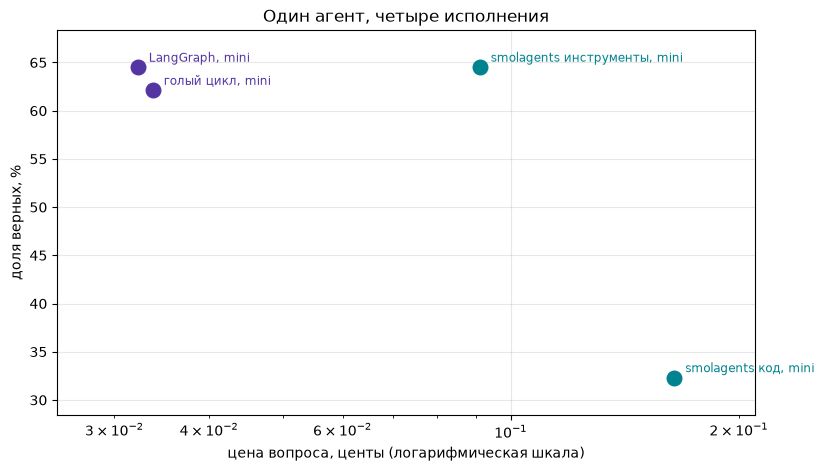

In [34]:
def color_of(tag):
    return COLORS["red"] if "каскад" in tag else COLORS["amber"] if "Sonnet" in tag else COLORS["teal"] if "smolagents" in tag else COLORS["violet"]

def money_chart(tags, path, title):
    table = report(tags)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.set_xscale("log")
    for _, r in table.iterrows():
        ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=110, color=color_of(r["конфигурация"]), zorder=3)
    ax.margins(x=0.15, y=0.12)
    fig.canvas.draw()
    placed = []
    for _, r in table.sort_values("центов на вопрос").iterrows():
        for dx, dy in [(8, 4), (8, -12), (-8, 4), (-8, -12), (8, 16), (8, -24)]:
            label = ax.annotate(r["конфигурация"], (r["центов на вопрос"], r["доля"] * 100), xytext=(dx, dy), textcoords="offset points",
                                fontsize=8.5, ha="left" if dx > 0 else "right", color=color_of(r["конфигурация"]))
            box = label.get_window_extent()
            if not any(box.overlaps(b) for b in placed) or dy == -24:
                break
            label.remove()
        placed.append(box)
    ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
    ax.set_title(title); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return table

money_chart(["голый цикл, mini", "LangGraph, mini", "smolagents инструменты, mini", "smolagents код, mini"],
            "img/money_frameworks.png", "Один агент, четыре исполнения")

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",77/124,0.621,3.7,1987,0.0337,0.0543
1,"LangGraph, mini",80/124,0.645,3.7,1902,0.0322,0.0499
2,"smolagents инструменты, mini",80/124,0.645,4.5,8335,0.0910,0.1411
3,"LangGraph + критик, mini",84/124,0.677,6.6,3869,0.0642,0.0948
4,"голосование 3, mini",82/124,0.661,11.2,6161,0.1016,0.1536
5,"каскад: 3 голоса mini, иначе Sonnet",93/124,0.750,13.9,9613,1.3123,1.7497
6,"LangGraph, Sonnet",95/124,0.766,3.6,4455,1.6347,2.1338


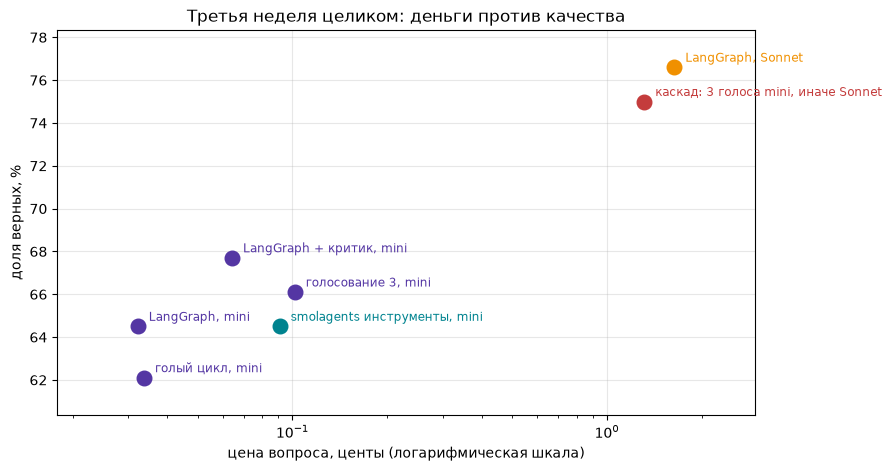

In [35]:
ALL = ["голый цикл, mini", "LangGraph, mini", "smolagents инструменты, mini", "LangGraph + критик, mini",
       "голосование 3, mini", "каскад: 3 голоса mini, иначе Sonnet", "LangGraph, Sonnet"]
money_chart(ALL, "img/money_all.png", "Третья неделя целиком: деньги против качества")

In [36]:
final = report(ALL + ["LangGraph как есть, mini", "smolagents код, mini"])
final.insert(1, "вопросов", [len(RESULTS[t]) for t in final["конфигурация"]])
final.insert(3, "верно на первых 40", [sum(r["ok"] for r in RESULTS[t][:40]) for t in final["конфигурация"]])
final.to_csv("results_table.csv", index=False)
print("ушло наверх:", len(ESCALATED), "из", STRONG_SAMPLE, "| потрачено за весь ноутбук, $:", round(sum(c["cost"] for c in CALLS), 2))
final

ушло наверх: 78 из 124 | потрачено за весь ноутбук, $: 4.31


,конфигурация,вопросов,верно,верно на первых 40,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",124,77/124,27,0.621,3.7,1987,0.0337,0.0543
1,"LangGraph, mini",124,80/124,27,0.645,3.7,1902,0.0322,0.0499
2,"smolagents инструменты, mini",124,80/124,26,0.645,4.5,8335,0.0910,0.1411
3,"LangGraph + критик, mini",124,84/124,29,0.677,6.6,3869,0.0642,0.0948
4,"голосование 3, mini",124,82/124,27,0.661,11.2,6161,0.1016,0.1536
5,"каскад: 3 голоса mini, иначе Sonnet",124,93/124,31,0.750,13.9,9613,1.3123,1.7497
6,"LangGraph, Sonnet",124,95/124,31,0.766,3.6,4455,1.6347,2.1338
7,"LangGraph как есть, mini",124,61/124,21,0.492,4.4,2647,0.0421,0.0857
8,"smolagents код, mini",124,40/124,10,0.323,5.0,15771,0.1643,0.5095


## Шаг 5. Потолок на деньги

`ModelCallLimitMiddleware` обрывает прогон после заданного числа вызовов модели (в коде, не в промпте). Вопрос, на котором потолок сработал, и что агент ответил после обрыва.

In [ ]:
from langchain.agents.middleware import ModelCallLimitMiddleware

TAG["now"] = "бюджет"
capped = create_agent(lc_model(CHEAP), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM,
                      middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")])
out = capped.invoke({"messages": [{"role": "user", "content": "Compare the months of the 2026 Winter Olympics and the 2026 FIFA World Cup, then list three events of each."}]})
print(out["messages"][-1].content[:300])
print("вызовов модели:", sum(c["tag"] == "бюджет" for c in CALLS))

Model call limits exceeded: run limit (2/2)
вызовов модели: 2
